# ANA-072: provenance, objective replay and the completed search
This notebook independently checks the completed RUN-186 archive and its
calibration bookkeeping. It performs no fitting, ML training or search task.
The old RUN-180 solutions are controls and warm starts, not newly discovered
optima. Execution consistency is separate from biological adequacy.

In [1]:
from pathlib import Path
import hashlib, json, sqlite3, sys, tempfile, platform, importlib.metadata
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from scipy.special import expit
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'labproject.yaml').exists())
ANA = ROOT / 'analyses/2026-11-25_ANA-072_run-186-trpb-landscape-behaviour-architecture-and-difficulty-proxies'
RUN = ROOT / 'data/processed/aggregate-thermodynamic-gnk-calibration/RUN-186'
OUT = RUN / 'outputs'; SOURCE = RUN / 'frozen_runtime/source'
INPUT = SOURCE / 'data/processed/interaction-strength-exp065-inputs'
TABLES = ANA / 'tables'; FIGURES = ANA / 'figures'
TABLES.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
def read(path): return json.loads(path.read_text())
def sha(path): return hashlib.sha256(path.read_bytes()).hexdigest()
def dump(name, value): (TABLES / name).write_text(json.dumps(value, indent=2, allow_nan=False) + '\n')
checks = {}; manifest = read(OUT / 'manifest.json')
selected = read(OUT / 'selected_parameters.json')
config = yaml.safe_load((OUT / 'config.yaml').read_text())

## Verify the immutable data and source
All remote output/log hashes, manifest-listed outputs and frozen runtime payloads
must agree. The genotype mask and seed cohorts retain the original design.
Confirmation cubes have already been inspected in earlier analyses; they are not
a new biological validation dataset.

In [2]:
collection = read(RUN / 'collection_verification.json')
for name, digest in collection['files'].items(): assert sha(RUN / name) == digest, name
for name, digest in manifest['files'].items(): assert sha(OUT / name) == digest, name
frozen = read(RUN / 'frozen_runtime/prelaunch_manifest.json')
for name, digest in frozen['files'].items(): assert sha(RUN / 'frozen_runtime' / name) == digest, name
for name in ('labproj-exit-code.txt', 'joint-readout-scientific-exit-code.txt'):
    assert (RUN / 'logs' / name).read_text().strip() == '0'
assert not (RUN / 'logs/stderr.txt').read_text().strip()
empirical = np.load(OUT / 'TrpB_empirical.npz', allow_pickle=False)
assert int(empirical['valid'].sum()) == 159129
assert empirical['genotypes'].shape == (160000, 4)
seeds = pd.read_csv(OUT / 'seed_audit.csv')
cal_index = pd.read_csv(OUT / 'latent_calibration_index.csv')
assert seeds.cohort.value_counts().to_dict() == {'reused': 16, 'fresh': 8}
assert not set(seeds.seed) & set(cal_index.seed)
assert config['ratio_bounds'] == [0., 8.] and 'interaction_ratios' not in config
assert all(s['interaction_concentration'] is None for s in selected)
checks['archive'] = dict(remote_files=len(collection['files']), output_files=len(manifest['files']),
    frozen_payloads=len(frozen['files']), masked_genotypes=159129, all_hashes_match=True,
    reused_seeds=16, fresh_seeds=8, calibration_confirmation_seed_overlap=False,
    gamma_concentration_enabled=False, both_exit_codes_zero=True)
print(checks['archive'])

{'remote_files': 93, 'output_files': 86, 'frozen_payloads': 339, 'masked_genotypes': 159129, 'all_hashes_match': True, 'reused_seeds': 16, 'fresh_seeds': 8, 'calibration_confirmation_seed_overlap': False, 'gamma_concentration_enabled': False, 'both_exit_codes_zero': True}


## All trials and selected parameters agree across three records
SQLite is opened read-only. The compressed CSV and the selected-parameter record
must agree with it. A continuous search is verified by the distribution metadata
and the sampled off-grid values. Completing a fixed budget does not prove
convergence or global optimality.

In [3]:
trace_by_mode = {}; trial_checks = []
for setting in selected:
    mode = setting['observation']
    trace = pd.read_csv(OUT / 'fits' / setting['trial_history'])
    with sqlite3.connect((OUT / 'fits' / setting['sqlite_history']).as_uri() + '?mode=ro', uri=True) as db:
        rows = pd.read_sql_query('SELECT t.trial_id,t.number,t.state,v.value FROM trials t JOIN trial_values v ON t.trial_id=v.trial_id ORDER BY t.number', db)
        params = pd.read_sql_query('SELECT t.number,p.param_name,p.param_value,p.distribution_json FROM trial_params p JOIN trials t ON p.trial_id=t.trial_id', db)
    assert len(rows) == len(trace) == setting['evaluations'] == 11712
    assert rows.state.eq('COMPLETE').all()
    np.testing.assert_array_equal(rows.number, trace.evaluation)
    np.testing.assert_allclose(rows.value, trace.total, rtol=1e-13, atol=1e-14)
    wide = params.pivot(index='number', columns='param_name', values='param_value')
    for name in ('r', 'p0', 'p1', 'p2', 'p3'):
        np.testing.assert_allclose(wide[name], trace[name], rtol=1e-13, atol=1e-14)
    for encoded in params.loc[params.param_name.eq('r'), 'distribution_json'].unique():
        distribution = json.loads(encoded)
        assert distribution['name'] == 'FloatDistribution'
        assert distribution['attributes'] == {'step': None, 'low': 0.0, 'high': 8.0, 'log': False}
    best = trace.loc[trace.total.idxmin()]
    assert int(best.evaluation) == setting['selected_trial']
    np.testing.assert_allclose(best.total, setting['objective']['total'], rtol=1e-13)
    np.testing.assert_allclose(best[['p0','p1','p2','p3']].to_numpy(float), setting['parameters'], rtol=1e-13)
    assert float(best.r) == setting['ratio']
    adaptive = trace.loc[~trace.candidate.str.startswith('RUN180')]
    assert len(adaptive) == 11706
    exact_best = float(rows.value.min())
    trial_checks.append(dict(observation=mode, complete=len(trace), failed=0,
        off_grid_trials=int((~trace.r.isin([0,.5,1,2,4,8])).sum()),
        selected_trial=int(best.evaluation), selected_r=float(best.r), loss=exact_best,
        best_new_candidate_loss=float(adaptive.total.min()), selected_source=setting['selected_source'],
        loss_improvement_over_warm_start=float(setting['warm_start_objective']-exact_best)))
    trace_by_mode[mode] = trace
pd.DataFrame(trial_checks).to_csv(TABLES / 'validation_search_summary.csv', index=False)
checks['trials'] = trial_checks
pd.DataFrame(trial_checks)

,observation,complete,failed,off_grid_trials,selected_trial,selected_r,loss,best_new_candidate_loss,selected_source,loss_improvement_over_warm_start
0,none,11712,0,11706,4,4.0,0.137553,0.141893,RUN180_r4_warm_start,0.0
1,independent_difference,11712,0,11706,3,2.0,0.060749,0.064030,RUN180_r2_warm_start,0.0
2,shared_stop_sensitivity,11712,0,11706,1,0.5,0.030995,0.033968,RUN180_r0.5_warm_start,0.0


## Recompute the restored loss from native fitness values
The three equally weighted terms are: 101-quantile squared error divided by
empirical calibration variance; squared relative error in mean within-cube SD;
and squared error in the near-floor mass. Frozen observation banks are rebuilt
from the archived donor assignments and uniforms. The loss arithmetic below is
written independently of the optimizer's objective function.

In [4]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(SOURCE / 'scripts'))
sys.path.insert(0, str(SOURCE / 'external/Adapt-Env'))
from replicate_observation_exp065 import calibrate_noise
from observation_calibration_exp065 import observation_bank
from adaptenv import ThermodynamicConfig, ThermodynamicLandscape
import replicate_observation_exp065
assert Path(replicate_observation_exp065.__file__).resolve().is_relative_to(SOURCE)
original = yaml.safe_load((INPUT / 'config.yaml').read_text())
sub = INPUT / 'TrpB'
with tempfile.TemporaryDirectory(prefix='ana072-noise-') as tmp:
    noise, _ = calibrate_noise(pd.read_csv(sub / 'donor_assignments.csv.gz'),
        set(read(sub / 'excluded_noise_donors.json')), original, Path(tmp))
    rebuilt = read(Path(tmp) / 'noise_model.json'); recorded = read(OUT / 'noise/noise_model.json')
    for key in ('depth_breaks','fitness_breaks','shared_covariance_raw'):
        np.testing.assert_allclose(rebuilt[key], recorded[key], rtol=0, atol=1e-14)
uniforms = np.load(sub / 'fit_observation_uniforms.npz', allow_pickle=False)['uniforms']
banks = {'none': None, 'independent_difference': observation_bank(noise, uniforms, False),
         'shared_stop_sensitivity': observation_bank(noise, uniforms, True)}
panel = np.load(sub / 'empirical_panel.npz', allow_pickle=False)
panel_index = pd.read_csv(sub / 'empirical_panel_index.csv')
cal = panel['fitness'][panel_index.split.eq('calibration')]
latent = np.load(OUT / 'latent_calibration.npz', allow_pickle=False)
origin, scale, floor = (selected[0][k] for k in ('calibration_origin','calibration_scale','near_floor_raw'))
target = (cal-origin)/scale; q = np.linspace(0,1,101)
def independent_parts(mode, ratio, p):
    raw = origin+scale*(p[0]+np.exp(p[1])*expit(p[2]+np.exp(p[3])*(latent['a']+ratio*latent['g'])))
    bank = banks[mode]
    if bank is not None:
        arrays, breaks = bank
        bins = np.searchsorted(breaks, raw, side='right')
        errors = np.stack([arrays[bins[c,n], :2, :, c, n] for c in range(raw.shape[0]) for n in range(raw.shape[1])])
        errors = errors.reshape(*raw.shape, 2, arrays.shape[2]).transpose(2,3,0,1)
        y = ((raw+errors[0]+raw+errors[1])/2-origin)/scale
    else: y = (raw-origin)/scale
    parts = dict(quantile=float(np.mean((np.quantile(y,q)-np.quantile(target,q))**2)/target.var()),
        mean_sd=float((y.std(axis=-1).mean()/target.std(axis=-1).mean()-1)**2),
        floor_cdf=float(((y <= (floor-origin)/scale).mean()-(target <= (floor-origin)/scale).mean())**2))
    parts['total'] = sum(parts.values()); return parts
replays = []
warm = read(OUT / 'warm_start_parameters.json')
for s in warm:
    parts = independent_parts(s['observation'],s['ratio'],s['parameters'])
    for key,value in parts.items(): np.testing.assert_allclose(value,s['objective'][key],rtol=1e-12,atol=1e-14)
    replays.append(dict(observation=s['observation'],ratio=s['ratio'],**parts))
for setting in selected:
    mode=setting['observation'];trace=trace_by_mode[mode]
    for idx in np.unique(np.r_[setting['selected_trial'],np.linspace(6,len(trace)-1,5,dtype=int)]):
        row=trace.iloc[int(idx)]
        parts=independent_parts(mode,float(row.r),[float(row[f'p{i}']) for i in range(4)])
        for key,value in parts.items(): np.testing.assert_allclose(value,row[key],rtol=1e-11,atol=1e-13)
pd.DataFrame(replays).to_csv(TABLES / 'validation_objective_replay.csv',index=False)
checks['objective'] = dict(historical_settings_replayed=len(replays), selected_and_sampled_trials_replayed=18,
    quantiles=101, equal_term_weights=True, target_calibration_cubes=len(cal), observation_draws=uniforms.shape[0])
print(checks['objective'])

{'historical_settings_replayed': 18, 'selected_and_sampled_trials_replayed': 18, 'quantiles': 101, 'equal_term_weights': True, 'target_calibration_cubes': 32, 'observation_draws': 8}


## Replay all 24 latent fields and compare with the historical selected fits
This also verifies that the archived model is Gaussian, full pairwise and profile
conditioned. Numerical tolerances accommodate the recorded Mac/Linux roundoff.
Identical selected parameters imply no new optimum; table comparisons assess
whether the downstream descriptors reproduce the old selected regimes.

In [5]:
matrix = np.load(OUT / 'additive_matrix.npy',allow_pickle=False)
field_checks=[]
for row in seeds.itertuples():
    model=ThermodynamicLandscape(ThermodynamicConfig(length=4,seed=int(row.seed),**config['model']), additive_matrix=matrix)
    a,g=model.latent_components(empirical['genotypes'])
    saved=np.load(OUT / 'latent_fields' / f'TrpB_{row.seed}.npz',allow_pickle=False)
    np.testing.assert_allclose(a,saved['a'],rtol=1e-13,atol=1e-14)
    np.testing.assert_allclose(g,saved['g'],rtol=1e-13,atol=1e-14)
    np.testing.assert_array_equal(model.reference,json.loads(row.reference))
    assert model.config.interaction_concentration is None and model.field.term_counts=={2:6}
    field_checks.append(dict(seed=int(row.seed),maximum_a_difference=float(np.max(abs(a-saved['a']))),
        maximum_g_difference=float(np.max(abs(g-saved['g'])))))
old=SOURCE / 'data/processed/aggregate-thermodynamic-gnk-calibration/RUN-180/outputs'
historical=read(old/'selected_parameters.json')
for s in selected:
    prev=next(x for x in historical if x['observation']==s['observation'] and x['ratio']==s['ratio'])
    np.testing.assert_array_equal(s['parameters'],prev['parameters'])
comparisons=[]
keys=['seed','cohort','ratio','observation','layer','relative_resolution']
for name in ['graph_summary.csv','cube_summary.csv']:
    current=pd.read_csv(OUT/name);previous=pd.read_csv(old/name)
    matched=current.merge(previous,on=keys,suffixes=('_current','_old'),validate='one_to_one')
    assert len(matched)==len(current)
    numeric=[c for c in current.select_dtypes('number') if c not in keys]
    differences={}
    for col in numeric:
        left=matched[col+'_current'].to_numpy();right=matched[col+'_old'].to_numpy()
        np.testing.assert_allclose(left,right,rtol=1e-10,atol=1e-12,equal_nan=True)
        finite=np.isfinite(left)&np.isfinite(right)
        differences[col]=float(np.max(abs(left[finite]-right[finite]))) if finite.any() else 0.
    comparisons.append(dict(file=name,rows=len(current),maximum_absolute_difference=max(differences.values()),by_column=differences))
checks['model_replay'] = dict(seeds=24,genotypes_per_seed=160000,
    maximum_a_difference=max(x['maximum_a_difference'] for x in field_checks),
    maximum_g_difference=max(x['maximum_g_difference'] for x in field_checks),
    selected_parameters_equal_RUN180=True, historical_descriptor_comparisons=comparisons)
pd.DataFrame(field_checks).to_csv(TABLES/'validation_latent_replay.csv',index=False)
print({k:v for k,v in checks['model_replay'].items() if k!='historical_descriptor_comparisons'})

{'seeds': 24, 'genotypes_per_seed': 160000, 'maximum_a_difference': 0.0, 'maximum_g_difference': 2.220446049250313e-15, 'selected_parameters_equal_RUN180': True}


## Supplementary figure: the joint search did not improve the old fits
Every trial is retained. The optimizer searched continuous r and four readout
coordinates, but the best historical candidate remains selected in every mode.
This is a result about this completed search, not proof that a better fit does
not exist or that one optimizer is generally superior.

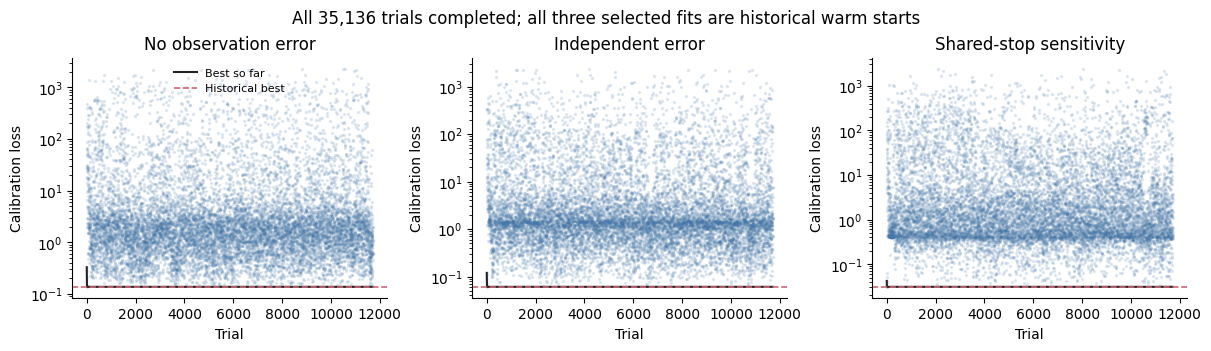

All validation assertions passed.


In [6]:
labels={'none':'No observation error','independent_difference':'Independent error','shared_stop_sensitivity':'Shared-stop sensitivity'}
fig,axes=plt.subplots(1,3,figsize=(12,3.4),layout='constrained')
for ax,s in zip(axes,selected):
    t=trace_by_mode[s['observation']]
    ax.scatter(t.evaluation+1,t.total,s=2,alpha=.13,color='#4477AA',rasterized=True)
    ax.plot(t.evaluation+1,t.total.cummin(),color='#222222',lw=1.5,label='Best so far')
    ax.axhline(s['warm_start_objective'],color='#CC6677',ls='--',lw=1.2,label='Historical best')
    ax.set(xlabel='Trial',ylabel='Calibration loss',yscale='log',title=labels[s['observation']])
    ax.spines[['top','right']].set_visible(False)
axes[0].legend(frameon=False,fontsize=8)
fig.suptitle('All 35,136 trials completed; all three selected fits are historical warm starts',fontsize=12)
for suffix in ('png','pdf'):fig.savefig(FIGURES/f'07_joint_search.{suffix}',dpi=180,bbox_inches='tight')
plt.show()
checks['scope'] = 'Engineering verification only; not convergence, new biological validation or a learning/search benchmark.'
dump('validation_checks.json',checks)
dump('analysis_environment.json',{'python':platform.python_version(),'executable':sys.executable,
    'platform':platform.platform(),'packages':{d.metadata['Name']:d.version for d in importlib.metadata.distributions()}})
print('All validation assertions passed.')